# Treinamento de Modelo de Reconhecimento de Gestos

Este notebook treina um modelo de Machine Learning simples (Random Forest) para identificar tipos de gestos baseados nas coordenadas das landmarks da mão capturadas pelo MediaPipe.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

## 1. Carregamento dos Dados

In [12]:
# Carregar o dataset
df = pd.read_csv('hand_landmarks_data.csv')

print(f"Formato do dataset: {df.shape}")
df.head()

Formato do dataset: (805, 64)


,x0,y0,z0,x1,y1,z1,x2,y2,z2,x3,...,x18,y18,z18,x19,y19,z19,x20,y20,z20,label
0,0.838770,0.842409,-4.184299e-07,0.806366,0.735675,0.004808,0.752845,0.645284,0.000435,0.713953,...,0.604772,0.882250,-0.030461,0.567076,0.903358,-0.026571,0.535516,0.916517,-0.023907,hangloose
1,0.835731,0.832796,-7.131471e-07,0.792211,0.756590,0.020134,0.731266,0.694445,0.022428,0.693240,...,0.597496,0.861717,-0.051825,0.554328,0.897037,-0.054038,0.512512,0.923647,-0.055086,hangloose
2,0.834243,0.818259,-9.857785e-07,0.754533,0.824748,0.008322,0.687525,0.791420,0.009311,0.639826,...,0.648595,0.745446,-0.060993,0.608825,0.765033,-0.063670,0.580059,0.771666,-0.060323,hangloose
3,0.816013,0.846538,-8.649598e-07,0.756263,0.886147,-0.001409,0.672319,0.868489,0.003969,0.622644,...,0.685475,0.621586,-0.027219,0.646591,0.600507,-0.029383,0.612292,0.582779,-0.023520,hangloose
4,0.829251,0.808976,-8.034989e-07,0.767618,0.847264,-0.002702,0.682763,0.831471,-0.000313,0.631891,...,0.706714,0.575069,-0.038136,0.667574,0.545298,-0.042004,0.633329,0.519371,-0.037712,hangloose


In [13]:
# Verificar a balanço das classes
print("Quantidade de amostras por gesto:")
print(df['label'].value_counts())

Quantidade de amostras por gesto:
label
joinha         152
ok             101
rock            91
paz             82
coracao         80
va se foder     77
hangloose       76
nada            74
pare            72
Name: count, dtype: int64


## 2. Pré-processamento

In [14]:
# Separar features (X) e target (y)
X = df.drop('label', axis=1)
y = df['label']

# Codificar labels (texto para número)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes mapeadas:")
for i, item in enumerate(label_encoder.classes_):
    print(f"{item} -> {i}")

Classes mapeadas:
coracao -> 0
hangloose -> 1
joinha -> 2
nada -> 3
ok -> 4
pare -> 5
paz -> 6
rock -> 7
va se foder -> 8


In [15]:
# Split dos dados em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Amostras de treino: {len(X_train)}")
print(f"Amostras de teste: {len(X_test)}")

Amostras de treino: 644
Amostras de teste: 161


## 3. Treinamento do Modelo

In [16]:
# Inicializar e treinar o modelo Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


## 4. Avaliação do Modelo

In [17]:
# Previsões
y_pred = model.predict(X_test)

# Métricas
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia: {accuracy*100:.2f}%")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Acurácia: 90.06%

Relatório de Classificação:
              precision    recall  f1-score   support

     coracao       0.94      1.00      0.97        16
   hangloose       0.82      0.60      0.69        15
      joinha       0.83      1.00      0.91        30
        nada       0.85      0.73      0.79        15
          ok       0.95      0.95      0.95        20
        pare       1.00      1.00      1.00        15
         paz       0.84      0.94      0.89        17
        rock       1.00      0.83      0.91        18
 va se foder       0.93      0.93      0.93        15

    accuracy                           0.90       161
   macro avg       0.91      0.89      0.89       161
weighted avg       0.90      0.90      0.90       161



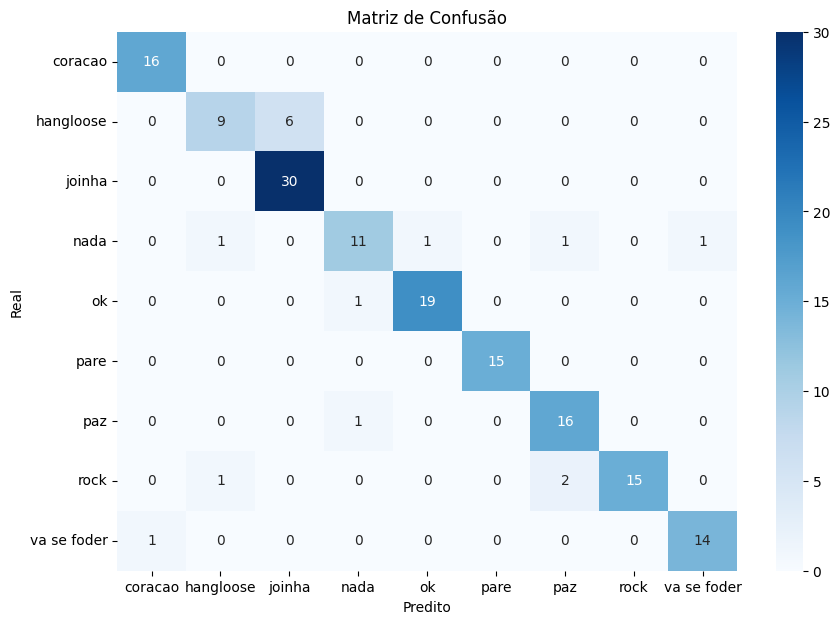

In [18]:
# Matriz de Confusão
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

## 5. Salvar o Modelo

In [19]:
# Salvar o modelo treinado e o label encoder
joblib.dump(model, 'gesture_model.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')

print("Modelo salvo como 'gesture_model.pkl'")
print("Label Encoder salvo como 'label_encoder.pkl'")

Modelo salvo como 'gesture_model.pkl'
Label Encoder salvo como 'label_encoder.pkl'
